# Holonomic light curve and fused gradients vs VBMicrolensing: wide planetary caustic

This is the second case in the comparison series: a wide binary (`s=1.2`, `q=0.01`) with a source trajectory aimed through the planetary caustic. It calls the ordinary main selector, preserving point-source and hexadecapole decisions and replacing only the integral branch with the caustic-seeded radial-frontier path. The comparison uses VBMicrolensing's `BinaryLightCurve` over 201 matching epochs and reports the selected route counts plus separate quadrature and support diagnostics.

The output figure shows both magnification curves over an extended time range, the local caustic encounter, and all seven parameter derivatives in separate full-width panels. The gradient call is separate from the value-only timing; gradient precision remains unchecked. Seed support and kernel support are reported independently.

## First run

Run these from the seeded-boundary-events repository root once. Build the native Python package from this worktree. The separate fused-gradient module is needed only for the derivative cell.

```bash
GSL_ROOT=/rogue1_8/nunota/local/gsl cmake -S . -B build-seeded-events/python-api \
  -DCMAKE_BUILD_TYPE=Release -DLCBININT_BUILD_PYTHON=ON \
  -DLCBININT_ENABLE_OPENMP=OFF -DLCBININT_ENABLE_JAX_FFI=OFF \
  -DLCBININT_BUILD_TESTS=OFF
cmake --build build-seeded-events/python-api --target lcbinint_python -j2
bash benchmarks/holonomic/fused_gradient/build.sh
```

The notebook bootstrap then loads the wrapper from this checkout and its native extension from the matching local build.

In [3]:
# Select this worktree's Python wrapper and native extension. The host has an
# editable lcbinint install, so bypass its import finder to avoid mixing branches.
import importlib.util
import os
import sys

# Keep native thread budgets matched for both timing paths.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = "1"
os.environ["OMP_DYNAMIC"] = "FALSE"
from pathlib import Path

ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "benchmarks/holonomic/fused_gradient/README.md").exists()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the seeded-boundary-events worktree")

BUILD_PYTHON = ROOT / "build-seeded-events/python-api"
BUILD_PACKAGE = BUILD_PYTHON / "lcbinint"
SOURCE_PACKAGE = ROOT / "python/lcbinint"
FUSED_PYTHON = ROOT / "build-seeded-events/fused-gradient/python"
if not list(BUILD_PACKAGE.glob("_lcbinint*.so")):
    raise RuntimeError(
        "Build the branch-local Python extension first; see the notebook's setup note."
    )
if not list(FUSED_PYTHON.glob("_lcbinint_holonomic_fused*.so")):
    raise RuntimeError("Run benchmarks/holonomic/fused_gradient/build.sh first")

cache = ROOT / "build-seeded-events/matplotlib-cache"
cache.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(cache)

for finder in list(sys.meta_path):
    known_sources = getattr(finder, "known_source_files", {})
    known_wheels = getattr(finder, "known_wheel_files", {})
    if "lcbinint" in known_sources and "lcbinint._lcbinint" in known_wheels:
        sys.meta_path.remove(finder)

sys.path[:] = [entry for entry in sys.path
               if entry != str(FUSED_PYTHON)]
sys.path.insert(0, str(FUSED_PYTHON))
for module_name in list(sys.modules):
    if module_name == "lcbinint" or module_name.startswith("lcbinint."):
        del sys.modules[module_name]
package_spec = importlib.util.spec_from_file_location(
    "lcbinint",
    SOURCE_PACKAGE / "__init__.py",
    submodule_search_locations=[str(SOURCE_PACKAGE), str(BUILD_PACKAGE)],
)
lcbinint = importlib.util.module_from_spec(package_spec)
sys.modules["lcbinint"] = lcbinint
package_spec.loader.exec_module(lcbinint)

import VBMicrolensing
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle

print("Python wrapper:", lcbinint.__file__)
print("Native module:", lcbinint._native.__file__)
print("Fused module:", FUSED_PYTHON)


Python wrapper: /rogue1_8/nunota/lcbinint/experiments/seeded-boundary-events/python/lcbinint/__init__.py
Native module: /rogue1_8/nunota/lcbinint/experiments/seeded-boundary-events/build-seeded-events/python-api/lcbinint/_lcbinint.cpython-310-x86_64-linux-gnu.so
Fused module: /rogue1_8/nunota/lcbinint/experiments/seeded-boundary-events/build-seeded-events/fused-gradient/python


In [4]:
from dataclasses import dataclass
import math

@dataclass(frozen=True)
class Case:
    s: float = 1.2
    q: float = 1.0e-2
    t0: float = 0.0
    tE: float = 1.0
    u0: float = 0.03
    alpha: float = -0.08
    rho: float = 3.0e-3
    limb_darkening_c: float = 0.5
    tau_min: float = -0.2
    tau_max: float = 0.8
    n_times: int = 201
    repeats: int = 21
    mu_atol: float = 1.0e-8
    mu_rtol: float = 1.0e-4

case = Case()
tau = np.linspace(case.tau_min, case.tau_max, case.n_times)
times = case.t0 + case.tE * tau
params = {
    "t0": case.t0,
    "u0": case.u0,
    "tE": case.tE,
    "alpha": case.alpha,
    "rho": case.rho,
    "q": case.q,
    "s": case.s,
}

curve = lcbinint.LightCurve(
    lens="binary",
    options=lcbinint.Options(
        param_type="vbm", nbin="auto",
        finite_source_tol=case.mu_atol, finite_source_reltol=case.mu_rtol,
    ),
    limb_darkening=lcbinint.LimbDarkening.linear(case.limb_darkening_c),
)
vbm = VBMicrolensing.VBMicrolensing()
vbm.Tol = case.mu_atol
vbm.RelTol = case.mu_rtol
vbm.a1 = case.limb_darkening_c
vbm.a2 = 0.0
vbm_params = [
    math.log(case.s), math.log(case.q), case.u0, case.alpha,
    math.log(case.rho), math.log(case.tE), case.t0,
]

print(f"{case.n_times} epochs over tau=[{case.tau_min:g}, {case.tau_max:g}]")
print(f"s={case.s:g}, q={case.q:g}, rho={case.rho:g}, gamma={case.limb_darkening_c:g}")
print(f"nominal integration tolerances: atol={case.mu_atol:g}, rtol={case.mu_rtol:g}")


201 epochs over tau=[-0.2, 0.8]
s=1.2, q=0.01, rho=0.003, gamma=0.5
nominal integration tolerances: atol=1e-08, rtol=0.0001


In [5]:
import statistics
import time

from lcbinint.holonomic_fused import lightcurve_value


def evaluate_holonomic_value():
    return lightcurve_value(
        curve, times, params, mu_atol=case.mu_atol, mu_rtol=case.mu_rtol
    )


vbm_times = times.tolist()


def evaluate_vbm():
    # Use VBM's full light-curve API, not a Python loop over BinaryMag.
    result = vbm.BinaryLightCurve(vbm_params, vbm_times)
    return np.asarray(result[0], dtype=float)


# One untimed warm-up per route. Alternate timed order to reduce drift bias.
_ = evaluate_holonomic_value()
_ = evaluate_vbm()
holonomic_samples = []
vbm_samples = []
for repetition in range(case.repeats):
    calls = (('holonomic', evaluate_holonomic_value), ('vbm', evaluate_vbm))
    if repetition % 2:
        calls = tuple(reversed(calls))
    for name, function in calls:
        start = time.perf_counter()
        value = function()
        elapsed = time.perf_counter() - start
        if name == 'holonomic':
            holonomic_value_result = value
            holonomic_samples.append(elapsed)
        else:
            vbm_values = value
            vbm_samples.append(elapsed)

holonomic_median = statistics.median(holonomic_samples)
vbm_median = statistics.median(vbm_samples)
relative_difference = np.abs(holonomic_value_result['mu'] - vbm_values) / np.maximum(
    np.abs(vbm_values), 1.0e-12
)
value_converged = np.asarray(holonomic_value_result['value_converged'], dtype=bool)
fully_converged = np.asarray(holonomic_value_result['fully_converged'], dtype=bool)
frontier_discovery_completed = np.asarray(
    holonomic_value_result['frontier_discovery_completed'], dtype=bool
)
support_certified = np.asarray(holonomic_value_result['support_certified'], dtype=bool)
radial_used = np.asarray(holonomic_value_result['integrator_used'], dtype=bool)
seed_support_proven = np.asarray(holonomic_value_result['seed_support_proven'], dtype=bool)
center_image_count = np.asarray(holonomic_value_result['center_image_count'], dtype=int)
augmented_seed_count = np.asarray(holonomic_value_result['augmented_seed_count'], dtype=int)

print(f'Value-only median per full light curve ({case.repeats} alternating repetitions; one warm-up per route excluded):')
print(f'  seeded holonomic: {1e3*holonomic_median:.3f} ms total, '
      f'{1e3*holonomic_median/case.n_times:.3f} ms/epoch')
print(f'  VBMicrolensing:   {1e3*vbm_median:.3f} ms total, '
      f'{1e3*vbm_median/case.n_times:.3f} ms/epoch')
print(f'  VBM / holonomic ratio: {vbm_median/holonomic_median:.3f}x '
      '(above 1 means the holonomic value-only route is faster)')
print('  both calls include per-epoch evaluation; holonomic also includes geometry '
      'and caustic-aware image-seed preparation.')
print('  LightCurve/VBM object construction and the separate gradient call are excluded.')
print()
print('Pointwise value comparison against this VBM configuration:')
print(f'  median relative difference = {np.nanmedian(relative_difference):.3e}')
print(f'  p95 relative difference    = {np.nanpercentile(relative_difference, 95):.3e}')
print(f'  maximum relative difference= {np.nanmax(relative_difference):.3e}')
print(f'  value route converged       = {value_converged.sum()}/{case.n_times}')
print(f'  fully converged incl support = {fully_converged.sum()}/{case.n_times}')
print(f'  main-selector radial epochs = {radial_used.sum()}/{case.n_times}')
print(f'  local frontier discovery    = {frontier_discovery_completed[radial_used].sum()}/{radial_used.sum()}')
print(f'  radial kernel support       = {support_certified[radial_used].sum()}/{radial_used.sum()}')
print(f'  caustic seed support proven = {seed_support_proven[radial_used].sum()}/{radial_used.sum()}')
diagnostic_caustics = curve.caustics(s=case.s, q=case.q)
caustic_x_parts = []
caustic_y_parts = []
for xs, ys in zip(diagnostic_caustics.x, diagnostic_caustics.y):
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    finite = np.isfinite(xs) & np.isfinite(ys)
    if np.any(finite):
        caustic_x_parts.append(xs[finite])
        caustic_y_parts.append(ys[finite])
caustic_points = np.column_stack((
    np.concatenate(caustic_x_parts), np.concatenate(caustic_y_parts)
))
sampled_source = curve.source_trajectory(times, params)
source_points = np.column_stack((
    np.asarray(sampled_source.x, dtype=float), np.asarray(sampled_source.y, dtype=float)
))
center_caustic_distance = np.sqrt(np.min(
    np.sum((source_points[:, None, :] - caustic_points[None, :, :]) ** 2, axis=2), axis=1
))
event_index = int(np.argmin(center_caustic_distance))
print(f"  closest sampled source-center approach tau={tau[event_index]:+.6f}: "
      f"distance to sampled caustic={center_caustic_distance[event_index]:.3e}, "
      f"rho={case.rho:g}, disk overlaps={center_caustic_distance[event_index] <= case.rho}")
print(f"    center images={center_image_count[event_index]}, seeds={augmented_seed_count[event_index]}, "
      f"seed support={seed_support_proven[event_index]}, "
      f"holonomic={holonomic_value_result['mu'][event_index]:.8g}, "
      f"VBM={vbm_values[event_index]:.8g}, rel={relative_difference[event_index]:.3e}")
print()
print('Five largest pointwise differences:')
for index in np.argsort(relative_difference)[-5:][::-1]:
    print(f"  tau={tau[index]:+.6f}  holonomic={holonomic_value_result['mu'][index]:.8g}  "
          f"VBM={vbm_values[index]:.8g}  rel={relative_difference[index]:.3e}  "
          f"converged={value_converged[index]}  kernel_support={support_certified[index]}  "
          f"center_images={center_image_count[index]}  seeds={augmented_seed_count[index]}  "
          f"seed_support={seed_support_proven[index]}  stop={holonomic_value_result['stop'][index]}")

Value-only median per full light curve (21 alternating repetitions; one warm-up per route excluded):
  seeded holonomic: 9.772 ms total, 0.049 ms/epoch
  VBMicrolensing:   49.964 ms total, 0.249 ms/epoch
  VBM / holonomic ratio: 5.113x (above 1 means the holonomic value-only route is faster)
  both calls include per-epoch evaluation; holonomic also includes geometry and caustic-aware image-seed preparation.
  LightCurve/VBM object construction and the separate gradient call are excluded.

Pointwise value comparison against this VBM configuration:
  median relative difference = 2.917e-06
  p95 relative difference    = 3.207e-05
  maximum relative difference= 5.146e-05
  value converged            = 201/201
  kernel support certified   = 0/201
  caustic seed support proven = 201/201
  closest sampled source-center approach tau=+0.025000: distance to sampled caustic=1.667e-04, rho=0.003, disk overlaps=True
    center images=5, seeds=95, seed support=True, holonomic=81.046785, VBM=81.04552

In [6]:
# Long, uniformly sampled display grid, independent of the 61 benchmark epochs.
# Its spacing is half the benchmark cadence, so the measured epochs land on it too.
plot_tau = np.linspace(-2.0, 2.0, 1601)
plot_times = case.t0 + case.tE * plot_tau
benchmark_plot_indices = np.rint(
    (tau - plot_tau[0]) / (plot_tau[1] - plot_tau[0])
).astype(int)
if not np.allclose(plot_tau[benchmark_plot_indices], tau, rtol=0.0, atol=1e-12):
    raise RuntimeError("The display grid must include every benchmark epoch")

plot_result = lightcurve_value(
    curve, plot_times, params, mu_atol=case.mu_atol, mu_rtol=case.mu_rtol
)
plot_mu = np.where(plot_result['value_converged'], plot_result['mu'], np.nan)
plot_vbm_result = vbm.BinaryLightCurve(vbm_params, plot_times.tolist())
plot_vbm_values = np.asarray(plot_vbm_result[0], dtype=float)

trajectory = curve.source_trajectory(plot_times, params)
trajectory_x = np.asarray(trajectory.x, dtype=float)
trajectory_y = np.asarray(trajectory.y, dtype=float)
caustics = curve.caustics(s=case.s, q=case.q)
source_at_t0 = curve.source_trajectory([case.t0], params)
source_center = (float(source_at_t0.x[0]), float(source_at_t0.y[0]))

### Caustic-crossing support check

A finite source can contain a fold-image pair even when its center has only three point images. The value-only holonomic call therefore uses the caustic-aware finite-source seed scan; it does not time a center-only shortcut. `seed_support_proven` reports the seeder's result separately from `support_certified`, the radial kernel's coverage flag.

## Parameter derivatives

The next cell makes a separate fused forward-gradient call over the same long plotting interval. It places seven short, full-width panels in a vertical stack below the full-width light curve, one for each model parameter. The gradient computation is not included in the value-only timing above. A `True` validity flag means the component is finite and usable under this experimental API, not that its numerical precision has been certified.

Separate gradient calculation over the display interval (excluded from value-only timing):
  valid gradient_precision_checked = False
  max relative primal difference at benchmark epochs = 6.375e-12
parameter      valid / display samples     finite-value range
      t0       1601 / 1601           [-1.4931e+04,  9.4923e+03]
      u0       1601 / 1601           [-2.7509e+04,  1.7064e+04]
      tE       1601 / 1601           [-2.9862e+02,  3.8609e+02]
   alpha       1601 / 1601           [-9.9811e+02,  7.9668e+02]
     rho       1601 / 1601           [-1.5771e+04,  1.2969e+04]
       q       1601 / 1601           [-2.8241e+04,  3.9291e+04]
       s       1601 / 1601           [-1.1216e+03,  1.3701e+03]


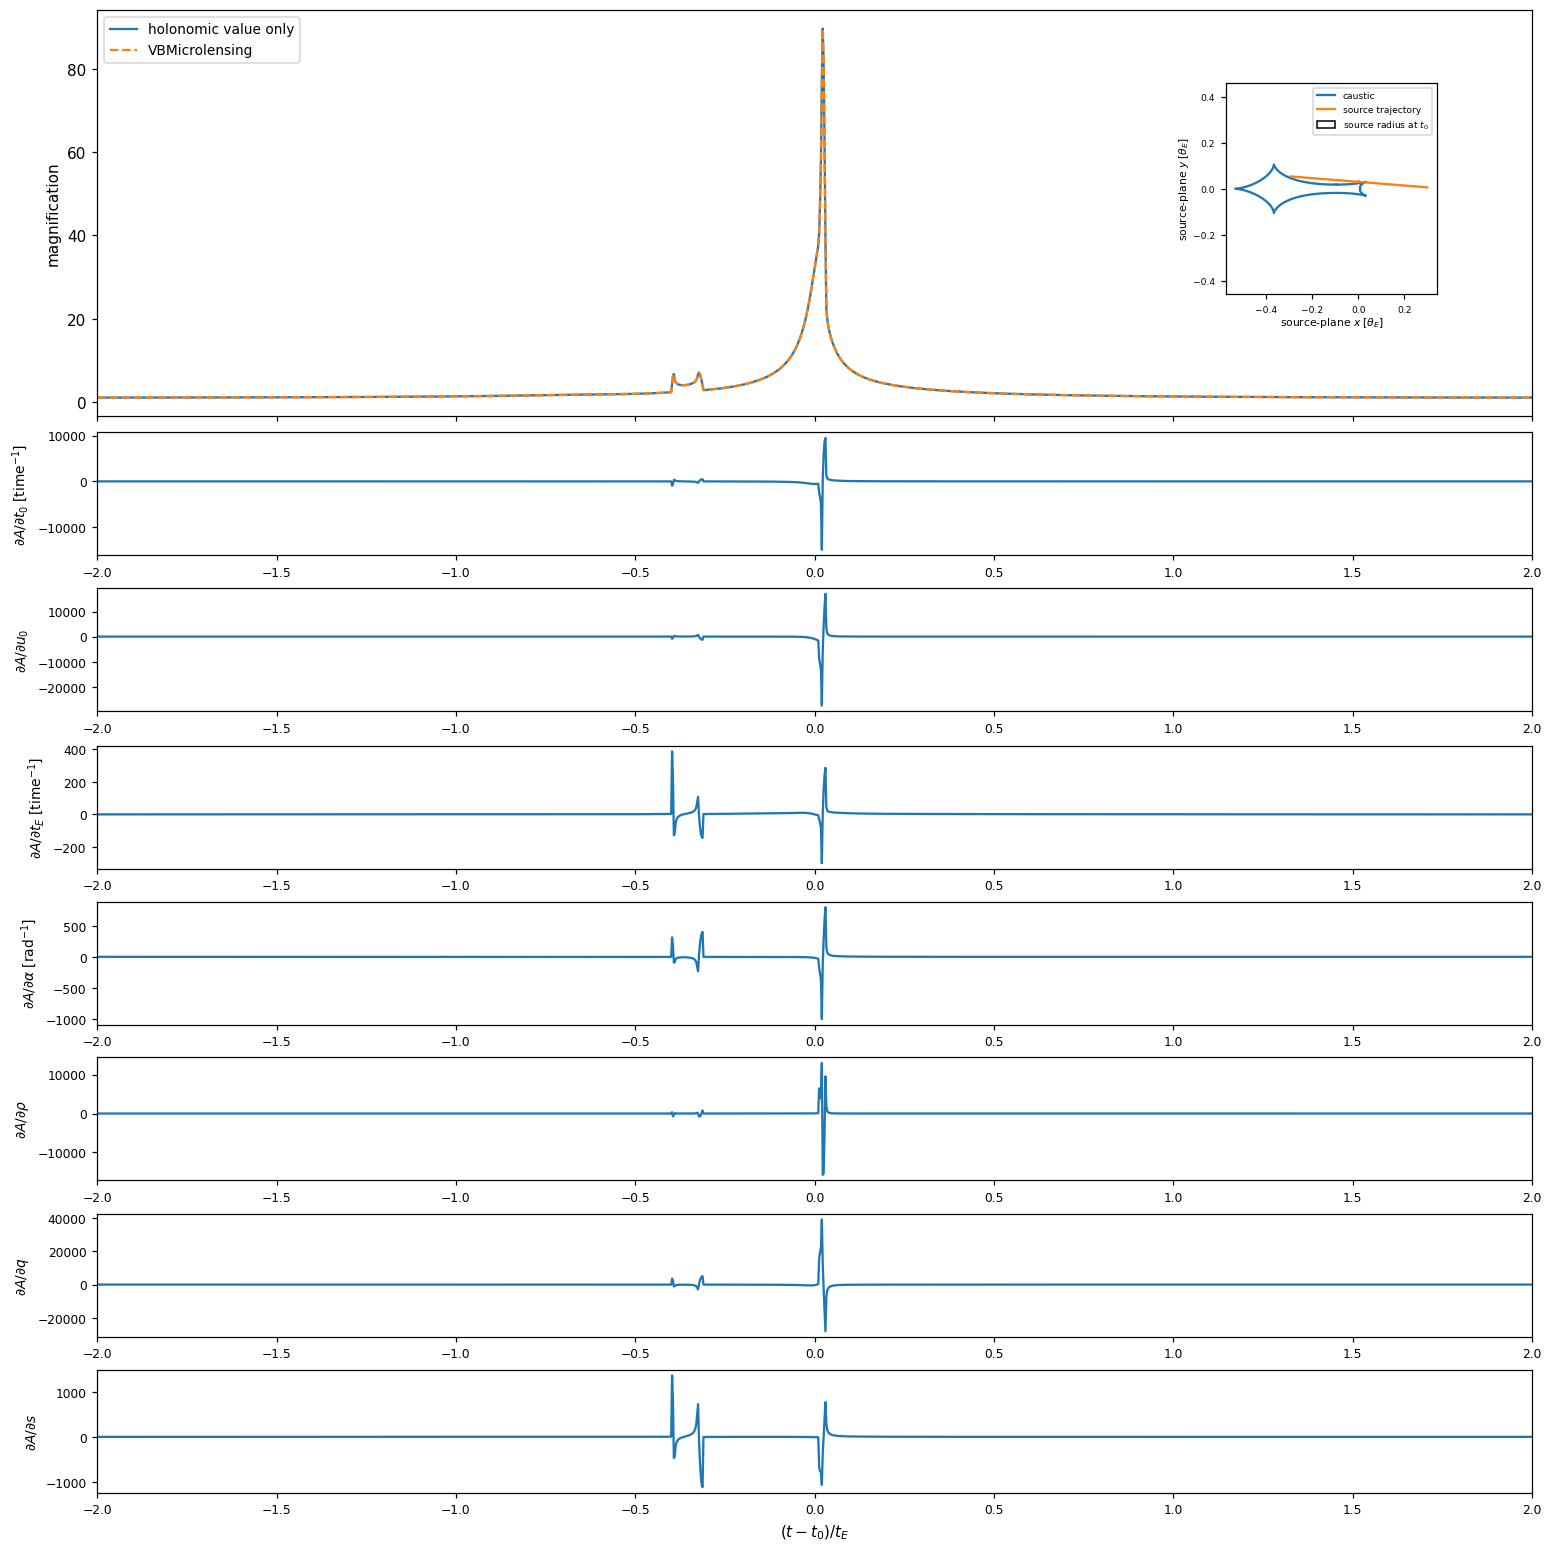

In [9]:
gradient_result = curve.holonomic_gradient(
    plot_times, params, mu_atol=case.mu_atol, mu_rtol=case.mu_rtol
)
gradient = np.asarray(gradient_result['grad_mu'], dtype=float)
parameter_order = list(gradient_result['param_order'])
gradient_valid = np.asarray(gradient_result['gradient_valid'], dtype=bool)
labels = {
    't0': r"$\partial A/\partial t_0$ [time$^{-1}$]",
    'u0': r"$\partial A/\partial u_0$",
    'tE': r"$\partial A/\partial t_E$ [time$^{-1}$]",
    'alpha': r"$\partial A/\partial \alpha$ [rad$^{-1}$]",
    'rho': r"$\partial A/\partial \rho$",
    'q': r"$\partial A/\partial q$",
    's': r"$\partial A/\partial s$",
}

print('Separate gradient calculation over the display interval (excluded from value-only timing):')
print(f"  valid gradient_precision_checked = {gradient_result['gradient_precision_checked']}")
gradient_primal_difference = np.abs(
    gradient_result['mu'][benchmark_plot_indices] - holonomic_value_result['mu']
) / np.maximum(np.abs(holonomic_value_result['mu']), 1.0e-12)
print(f'  max relative primal difference at benchmark epochs = {np.nanmax(gradient_primal_difference):.3e}')
print('parameter      valid / display samples     finite-value range')
for column, name in enumerate(parameter_order):
    valid = gradient_valid[:, column] & np.isfinite(gradient[:, column])
    values = gradient[valid, column]
    if values.size:
        print(f'{name:>8}       {valid.sum():>4} / {plot_times.size:<4}           '
              f'[{np.min(values): .4e}, {np.max(values): .4e}]')
    else:
        print(f'{name:>8}          0 / {plot_times.size:<4}           no valid samples')

# One full-width light curve, followed by seven full-width derivative strips.
fig = plt.figure(figsize=(14, 14), constrained_layout=True)
grid = fig.add_gridspec(8, 1, height_ratios=(3.3, 1, 1, 1, 1, 1, 1, 1))
ax_curve = fig.add_subplot(grid[0, 0])
axes = [fig.add_subplot(grid[row, 0], sharex=ax_curve) for row in range(1, 8)]

ax_curve.plot(plot_tau, plot_mu, label='holonomic value only')
ax_curve.plot(plot_tau, plot_vbm_values, linestyle='--', label='VBMicrolensing')
ax_curve.set_xlim(plot_tau[0], plot_tau[-1])
ax_curve.set_ylabel('magnification')
ax_curve.legend(fontsize=9, loc='upper left')
ax_curve.tick_params(labelbottom=False)

# Show the caustic encounter as a compact inset without narrowing the time panels.
ax_geometry = ax_curve.inset_axes([0.77, 0.30, 0.18, 0.52])
first_branch = True
caustic_x_parts = []
caustic_y_parts = []
for xs, ys in zip(caustics.x, caustics.y):
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    finite = np.isfinite(xs) & np.isfinite(ys)
    if np.any(finite):
        caustic_x_parts.append(xs[finite])
        caustic_y_parts.append(ys[finite])
        ax_geometry.plot(xs[finite], ys[finite], label='caustic' if first_branch else None)
        first_branch = False
local_trajectory = np.abs(plot_tau) <= 0.30
ax_geometry.plot(
    trajectory_x[local_trajectory], trajectory_y[local_trajectory],
    label='source trajectory',
)
ax_geometry.add_patch(Circle(
    source_center, case.rho, fill=False, linewidth=1.0,
    label=r'source radius at $t_0$',
))
geometry_x = np.concatenate([*caustic_x_parts, trajectory_x[local_trajectory]])
geometry_y = np.concatenate([*caustic_y_parts, trajectory_y[local_trajectory]])
x_center = 0.5 * (np.nanmin(geometry_x) + np.nanmax(geometry_x))
y_center = 0.5 * (np.nanmin(geometry_y) + np.nanmax(geometry_y))
half_extent = 0.55 * max(
    np.nanmax(geometry_x) - np.nanmin(geometry_x),
    np.nanmax(geometry_y) - np.nanmin(geometry_y),
)
ax_geometry.set_xlim(x_center - half_extent, x_center + half_extent)
ax_geometry.set_ylim(y_center - half_extent, y_center + half_extent)
ax_geometry.set_aspect('equal', adjustable='box')
ax_geometry.set_xlabel(r"source-plane $x\;[\theta_E]$", fontsize=7, labelpad=1)
ax_geometry.set_ylabel(r"source-plane $y\;[\theta_E]$", fontsize=7, labelpad=1)
ax_geometry.tick_params(labelsize=6)
ax_geometry.legend(fontsize=6, loc='upper right')

# Give each model parameter its own full-width derivative strip.
panel_parameters = ['t0', 'u0', 'tE', 'alpha', 'rho', 'q', 's']
for ax, name in zip(axes, panel_parameters):
    column = parameter_order.index(name)
    valid = gradient_valid[:, column] & np.isfinite(gradient[:, column])
    ax.plot(plot_tau, np.where(valid, gradient[:, column], np.nan))
    ax.set_ylabel(labels[name], fontsize=9, labelpad=4)
    ax.tick_params(axis='both', labelsize=8)
    ax.set_xlim(plot_tau[0], plot_tau[-1])
axes[-1].set_xlabel(r"$(t-t_0)/t_E$")

plt.show()